# Photo Retouch — Final Evaluation on the Test Set

Advanced Mathematics for Deep Learning final project.

The earlier notebooks chose every model and setting on the validation set:
`01_training.ipynb` up to the low-chroma refiner, and
`02_refinement.ipynb` for the experiments that followed. This
notebook measures the final methods once, on the 400 test images that were
set aside when the data were split and never used since. Nothing here is
trained or tuned.

## Evaluation Plan

Fixed before any test result was computed.

**Methods.** All at 128 × 128, the resolution of the dataset pipeline, and
all keep the original pixels outside the hole.

| Method | What it is |
| --- | --- |
| OpenCV Telea | Classical inpainting (radius 3); no learning |
| Coarse U-Net | Our deep U-Net trained with masked MAE: the pixel-error reference |
| Low-chroma refiner | Our final model: the gated-convolution refiner on the U-Net's fill (stage 1 of the app) |
| Pretrained diffusion | Stable Diffusion 1.5 Inpainting alone, at strength 1, where it ignores our fill |
| Our model + diffusion | The app's chain: the pretrained model starting from our fill, at strength 0.7 |

The diffusion model works at 512 × 512 on the image enlarged four times, and
its output is reduced back to 128 × 128. Its seed is the image's index. The
strength 0.7 was chosen by eye on four unlabeled `seg_pred` photos, not on
validation or test images.

**Measures**, defined as on validation; lower is better for all three:
masked MAE (pixel fidelity in the hole), perceptual distance (VGG16
features), and KID × 1000 (how far the results' distribution is from the
true images', with InceptionV3 features).

**Questions**, each answered with paired, image-by-image comparisons and 95%
bootstrap intervals over images:

1. Do our models beat the classical baseline? The coarse U-Net and the
   low-chroma refiner, each against OpenCV Telea.
2. What does the refiner change relative to the U-Net? The low-chroma
   refiner against the coarse U-Net.
3. What does the pretrained stage add to our model? Our model + diffusion
   against the low-chroma refiner.
4. Does our stage 1 help the pretrained model? Our model + diffusion against
   the pretrained diffusion alone.

**Reading the results.** A difference counts if its 95% interval excludes
zero. Between two of our trained models it must also exceed the difference
between two training runs of the same model, measured on validation: about
0.004 in masked MAE, while perceptual distance did not differ significantly
between runs. The intervals cover the choice of images, not the training run.
KID differences are read with the share of subsets in which one method is
lower; the subsets overlap, so that share is descriptive.

**Trial run.** Before the full run, a trial execution of this notebook on
every fourth test image (100), with 2 diffusion steps, checked the code. It
did compute metrics for those images; they were not used, and nothing in this
plan or in the methods was changed after it.

## Setup

The `photo_retouch` package must be installed in editable mode (see
ENVIRONMENT.md). The diffusion model needs about 2.1 GB of weights from the
Hugging Face Hub, downloaded once into the local cache.

In [1]:
import hashlib
import time
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import torch
from PIL import Image

from photo_retouch.data import (
    TEST_MANIFEST, TEST_MASKS, ValidationSet, fixed_masks, load_image_set,
    load_validation_set, reserved_test_selection,
)
from photo_retouch.device import configure_device
from photo_retouch.inpaint import (
    OurModel, inpaint, load_diffusion, refine_with_diffusion, to_uint8, torch_device,
)
from photo_retouch.metrics import Evaluator, masked_mae_per_image
from photo_retouch.models import (
    COARSE_MODEL_FILE, SAVED_REFINERS, load_saved_model, opencv_telea,
    predict_coarse, refine_images,
)
from photo_retouch.paths import MODEL_DIR, PROJECT_ROOT, latest_record_dir
from photo_retouch.plotting import show_comparison, show_zoom
from photo_retouch.records import save_or_check

TRAINING_DEVICE = configure_device()
print(f"TensorFlow {tf.__version__} on {TRAINING_DEVICE}; PyTorch {torch.__version__} on {torch_device()}")

TensorFlow 2.18.1 on /GPU:0; PyTorch 2.13.0 on mps


## The Reserved Test Set

The training notebook reserved 100 images per category from Kaggle's
`seg_test` folder, with `pd.Series(sorted files).sample(n=100,
random_state=42)`. It never evaluated anything on them and never saved the
list, so the same rule rebuilds it here. Each image gets one fixed mixed mask
(strokes, a rounded block, or a person silhouette) from the generator used
for training and validation, with seed 2060.

The first execution freezes the list and the masks in the snapshot's `test/`
folder; every later execution must rebuild exactly the same files.

In [2]:
RECORD_DIR = latest_record_dir()
TEST_RECORD_DIR = RECORD_DIR / "test"
TEST_SUBSET = None  # all 400 images

selection = reserved_test_selection()
masks = fixed_masks(len(selection))

TEST_RECORD_DIR.mkdir(parents=True, exist_ok=True)
if not (TEST_RECORD_DIR / TEST_MANIFEST).exists():
    selection.to_csv(TEST_RECORD_DIR / TEST_MANIFEST, index=False)
    np.savez_compressed(TEST_RECORD_DIR / TEST_MASKS, masks=masks)
assert pd.read_csv(TEST_RECORD_DIR / TEST_MANIFEST).equals(selection)
assert np.array_equal(np.load(TEST_RECORD_DIR / TEST_MASKS)["masks"], masks)

test_set = load_image_set(TEST_RECORD_DIR, TEST_MANIFEST, TEST_MASKS)
if TEST_SUBSET is not None:  # only for a quick trial run of the notebook
    subset = np.arange(len(test_set))[TEST_SUBSET]
    test_set = ValidationSet(
        test_set.record_dir, test_set.manifest.iloc[subset].reset_index(drop=True),
        test_set.originals[subset], test_set.masks[subset],
    )
validation = load_validation_set(RECORD_DIR)

print(f"Test images: {len(test_set)}", test_set.manifest["category"].value_counts().to_dict())
print(f"Mean hole coverage: test {test_set.masks.mean():.1%}, validation {validation.masks.mean():.1%}")

Test images: 400 {'sea': 100, 'forest': 100, 'street': 100, 'buildings': 100}
Mean hole coverage: test 14.0%, validation 13.7%


### Overlap with the Training and Validation Images

`seg_train` and `seg_test` are separate folders, but the same photo could
appear in both. Two checks against the 6,400 training and validation images:
identical files, and an identical coarse layout (16 × 16 grey thumbnail
thresholded at its mean), which also catches resized or re-encoded copies
but matches some different photos with a similar composition.

Identical files: 0


,test image,matching image,split
0,sea/23165.jpg,sea/13679.jpg,training
1,sea/23649.jpg,sea/17814.jpg,training
2,sea/23976.jpg,sea/13679.jpg,training
3,forest/22993.jpg,forest/8394.jpg,validation


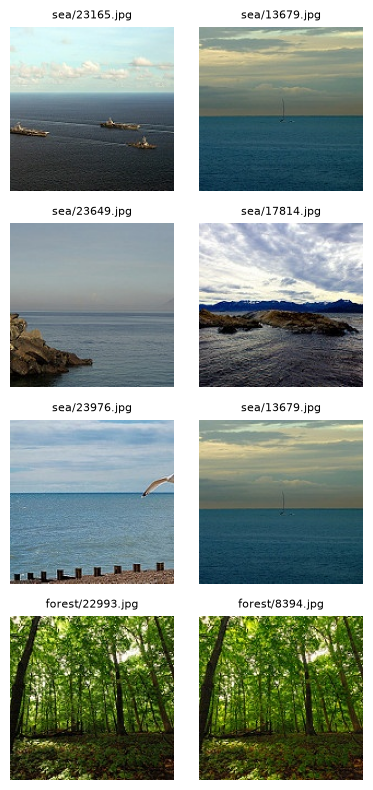

In [3]:
def file_digest(path):
    return hashlib.md5((PROJECT_ROOT / path).read_bytes()).hexdigest()


def layout_hash(path):
    grey = np.asarray(
        Image.open(PROJECT_ROOT / path).convert("L").resize((16, 16), Image.BOX), np.float32
    )
    return (grey > grey.mean()).tobytes()


used = pd.concat([
    pd.read_csv(RECORD_DIR / "train_6000.csv").assign(split="training"),
    pd.read_csv(RECORD_DIR / "validation_400.csv").assign(split="validation"),
])
used_files = set(used["path"].map(file_digest))
used_layouts = dict(zip(used["path"].map(layout_hash), zip(used["path"], used["split"])))

def short(path):
    return f"{Path(path).parent.name}/{Path(path).name}"


exact = [path for path in selection["path"] if file_digest(path) in used_files]
matches = pd.DataFrame([
    {"test image": path, "matching image": used_layouts[key][0], "split": used_layouts[key][1]}
    for path in selection["path"]
    if (key := layout_hash(path)) in used_layouts
])
print(f"Identical files: {len(exact)}")
display(matches.assign(**{
    column: matches[column].map(short) for column in ["test image", "matching image"]
}))

fig, axes = plt.subplots(len(matches), 2, figsize=(4, 2 * len(matches)))
for row, (_, match) in zip(np.atleast_2d(axes), matches.iterrows()):
    for axis, path in zip(row, [match["test image"], match["matching image"]]):
        axis.imshow(Image.open(PROJECT_ROOT / path))
        axis.set_title(short(path), fontsize=8)
        axis.axis("off")
fig.tight_layout()
plt.show()

No test file is identical to a training or validation file. Of the four
layout matches, three are different sea photos with a similar horizon. The
fourth, `forest/22993.jpg`, shows the same scene as the validation image
`forest/8394.jpg`, which no model was trained on but which was used to choose
models. The selection stays as reserved; the main results are also given
without that image.

In [4]:
NEAR_DUPLICATES = ["data/intel-image-classification/seg_test/seg_test/forest/22993.jpg"]
assert set(NEAR_DUPLICATES) <= set(matches["test image"])
print(f"Flagged near-duplicates in this run: {test_set.manifest['path'].isin(NEAR_DUPLICATES).sum()}")

Flagged near-duplicates in this run: 1


## Reconstruct the Test Set with Every Method

Our models and the OpenCV baseline run here in seconds. The diffusion
results take tens of minutes on the Apple M5, so they are cached in
`models/test_evaluation/` (ignored by Git) and read back on later
executions. Run time per image is recorded either way.

Two checks first: the packaged OpenCV baseline must reproduce the masked MAE
recorded for it on validation, and stage 1 of the app's pipeline must
reproduce the low-chroma refiner given the same 8-bit image (up to the final
8-bit rounding). The two diffusion methods take 8-bit images, as the app
does; the other methods take the dataset's float images, which changes our
refiner's output by a few levels in 255 at most.

In [5]:
COARSE_NAME = "Coarse U-Net"
REFINER_NAME = "Low-chroma refiner"
DIFFUSION_NAME = "Pretrained diffusion"
CHAIN_NAME = "Our model + diffusion"
METHODS = ["OpenCV Telea", COARSE_NAME, REFINER_NAME, DIFFUSION_NAME, CHAIN_NAME]
DIFFUSION_STRENGTHS = {DIFFUSION_NAME: 1.0, CHAIN_NAME: 0.7}
DIFFUSION_STEPS = 30
CACHE_DIR = MODEL_DIR / "test_evaluation"

saved_opencv = pd.read_csv(
    RECORD_DIR / "refinement" / "metric_summary.csv", index_col="method"
).loc["OpenCV Telea", "masked_mae"]
packaged_opencv = masked_mae_per_image(
    opencv_telea(validation), validation.originals, validation.masks
).mean()
print(f"OpenCV Telea on validation: recorded {saved_opencv:.6f}, packaged {packaged_opencv:.6f}")
assert abs(saved_opencv - packaged_opencv) < 1e-6

coarse_model = load_saved_model(COARSE_MODEL_FILE)
refiner_file, refine_fn = SAVED_REFINERS[REFINER_NAME]
refiner = load_saved_model(refiner_file)
reconstructions, seconds_per_image = {}, {}


def timed(name, compute):
    start = time.perf_counter()
    reconstructions[name] = compute()
    seconds_per_image[name] = (time.perf_counter() - start) / len(test_set)


timed("OpenCV Telea", lambda: opencv_telea(test_set))
timed(COARSE_NAME, lambda: predict_coarse(coarse_model, test_set))
timed(REFINER_NAME, lambda: refine_images(
    refiner, reconstructions[COARSE_NAME], test_set.masks, refine_fn
))

our_model = OurModel()
holes = test_set.masks[..., 0] > 0.5

# The app takes 8-bit photos: compare with the refiner on the same 8-bit input.
eight_bit = to_uint8(test_set.originals[:16]).astype(np.float32) / 255
check_masks = test_set.masks[:16]
check_visible = eight_bit * (1 - check_masks)
expected = refine_images(
    refiner,
    check_visible + coarse_model.predict(
        np.concatenate([check_visible, check_masks], axis=-1), verbose=0
    ) * check_masks,
    check_masks, refine_fn,
)
stage_one = np.stack([
    inpaint(image, hole, our_model).result
    for image, hole in zip(to_uint8(eight_bit), holes[:16])
]).astype(np.float32) / 255
gap = np.abs(check_visible + stage_one * check_masks - expected).max()
print(f"App stage 1 vs low-chroma refiner, largest difference: {gap * 255:.2f} / 255")
assert gap < 1 / 255

OpenCV Telea on validation: recorded 0.105255, packaged 0.105255


App stage 1 vs low-chroma refiner, largest difference: 0.50 / 255


In [6]:
pipe = load_diffusion()


def diffusion_results(name, strength):
    path = CACHE_DIR / f"{name.lower().replace(' ', '_').replace('+', 'and')}.npz"
    if path.exists():
        cached = np.load(path)
        assert cached["images"].shape[0] == len(test_set)
        assert float(cached["strength"]) == strength and int(cached["steps"]) == DIFFUSION_STEPS
        print(f"{name}: read from {path.relative_to(PROJECT_ROOT)}")
        return cached["images"], float(cached["seconds_per_image"])

    images, start = [], time.perf_counter()
    for index, (image, hole) in enumerate(zip(test_set.originals, holes)):
        refine = partial(
            refine_with_diffusion, pipe, strength=strength, steps=DIFFUSION_STEPS, seed=index
        )
        images.append(inpaint(to_uint8(image), hole, our_model, refine).result)
        if (index + 1) % 50 == 0:
            print(f"{name}: {index + 1}/{len(test_set)} images, "
                  f"{(time.perf_counter() - start) / (index + 1):.1f} s per image")
    images = np.stack(images)
    seconds = (time.perf_counter() - start) / len(test_set)
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        path, images=images, strength=strength, steps=DIFFUSION_STEPS, seconds_per_image=seconds
    )
    return images, seconds


for name, strength in DIFFUSION_STRENGTHS.items():
    images, seconds_per_image[name] = diffusion_results(name, strength)
    # Like every other method, keep the original pixels outside the hole.
    reconstructions[name] = test_set.compose(images.astype(np.float32) / 255)

display(pd.Series(seconds_per_image, name="seconds per image").round(3).to_frame())

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Pretrained diffusion: 50/400 images, 11.1 s per image


Pretrained diffusion: 100/400 images, 11.0 s per image


Pretrained diffusion: 150/400 images, 11.0 s per image


Pretrained diffusion: 200/400 images, 11.0 s per image


... (9 outputs left out)

Our model + diffusion: 300/400 images, 7.9 s per image


Our model + diffusion: 350/400 images, 7.9 s per image


Our model + diffusion: 400/400 images, 7.9 s per image


,seconds per image
OpenCV Telea,0.001
Coarse U-Net,0.002
Low-chroma refiner,0.007
Pretrained diffusion,10.933
Our model + diffusion,7.912


## Evaluate

The same measures as on validation. Grid components (jumps repeating every 2
or 4 px at fixed positions) and detail ratios (fine-detail energy relative to
the truth; 1 matches it) describe the texture.

In [7]:
evaluator = Evaluator(test_set)
evaluations = {name: evaluator.evaluate(reconstructions[name]) for name in METHODS}


def grid_by_period(images):
    table = pd.DataFrame(evaluator.grid_periodicity(images)).set_index("direction")
    return {
        f"grid {period} px ({direction[0]})": table.loc[direction, f"period {period} px"]
        for period in [2, 4] for direction in ["horizontal", "vertical"]
    }


metric_summary = pd.DataFrame(
    {name: evaluations[name].summary() for name in METHODS}
).T.rename_axis("method")
texture = pd.DataFrame({
    name: {**evaluator.detail_summary(images), **grid_by_period(images)}
    for name, images in {"True image": test_set.originals, **reconstructions}.items()
}).T.rename_axis("method")

PAIRS = [
    (COARSE_NAME, "OpenCV Telea"),
    (REFINER_NAME, "OpenCV Telea"),
    (REFINER_NAME, COARSE_NAME),
    (CHAIN_NAME, REFINER_NAME),
    (CHAIN_NAME, DIFFUSION_NAME),
]
paired = pd.DataFrame([
    {"method": method, "baseline": baseline,
     **evaluator.paired(evaluations[method], evaluations[baseline])}
    for method, baseline in PAIRS
]).set_index(["method", "baseline"])

categories = test_set.manifest["category"].to_numpy()
by_category = pd.DataFrame([
    {"method": name, "category": category,
     "masked_mae": evaluations[name].masked_mae[categories == category].mean(),
     "feature_distance": evaluations[name].feature_distance[categories == category].mean()}
    for name in METHODS for category in test_set.manifest["category"].unique()
]).set_index(["method", "category"])

keep = ~test_set.manifest["path"].isin(NEAR_DUPLICATES).to_numpy()
without_duplicates = pd.DataFrame({
    name: {"masked_mae": evaluations[name].masked_mae[keep].mean(),
           "feature_distance": evaluations[name].feature_distance[keep].mean()}
    for name in METHODS
}).T.rename_axis("method")

for table, filename in [
    (metric_summary, "metric_summary.csv"),
    (texture, "texture_and_grid.csv"),
    (paired, "paired_comparisons.csv"),
    (by_category, "category_summary.csv"),
    (without_duplicates, "summary_without_near_duplicates.csv"),
]:
    print(f"{filename}: {save_or_check(table, TEST_RECORD_DIR / filename)}")

with pd.option_context("display.width", 250, "display.max_columns", 20):
    display(metric_summary.round(4))
    display(paired.round(4))
    display(texture.round(4))
    display(by_category.unstack("category").round(4))
    display(without_duplicates.round(4))

metric_summary.csv: saved
texture_and_grid.csv: saved
paired_comparisons.csv: saved
category_summary.csv: saved
summary_without_near_duplicates.csv: saved


,masked_mae,feature_distance,kid_x1000,kid_x1000_std,low_freq_error,high_freq_error,texture_ratio_median
method,,,,,,,
OpenCV Telea,0.1049,1.0848,15.2161,3.5677,0.0626,0.0653,0.2526
Coarse U-Net,0.0915,0.8842,5.9868,2.3286,0.0508,0.0614,0.2213
Low-chroma refiner,0.1043,0.7142,0.3676,1.9627,0.0525,0.0772,0.8923
Pretrained diffusion,0.1380,0.8221,-0.6172,1.9962,0.0842,0.0858,0.9570
Our model + diffusion,0.1027,0.5957,-1.5482,1.8853,0.0552,0.0723,0.7647


masked_mae Δ   masked_mae 95% CI masked_mae images better  feature_distance Δ feature_distance 95% CI feature_distance images better  KID×1000 Δ KID subsets lower
method                baseline                                                                                                                                                                                
Coarse U-Net          OpenCV Telea               -0.0134  [-0.0150, -0.0119]                      88%             -0.2006      [-0.2183, -0.1830]                            91%     -9.2293              100%
Low-chroma refiner    OpenCV Telea               -0.0006  [-0.0023, +0.0011]                      48%             -0.3706      [-0.3970, -0.3456]                            96%    -14.8485              100%
                      Coarse U-Net                0.0128  [+0.0119, +0.0138]                       5%             -0.1699      [-0.1848, -0.1549]                            90%     -5.6192              100%
Our model + diffusion Low-chroma refiner         -0.0016  [-0.0033, -0.0000]                      48%             -0.1185      [-0.1357, -0.1019]                            76%     -1.9159               99%
                      Pretrained diffusion       -0.0352  [-0.0407, -0.0303]                      86%             -0.2263      [-0.2730, -0.1831]                            75%     -0.9310               88%

,luma_detail_ratio,chroma_detail_ratio,chroma_share,images_chroma_over_2x,grid 2 px (h),grid 2 px (v),grid 4 px (h),grid 4 px (v)
method,,,,,,,,
True image,1.0000,1.0000,0.0105,0.0000,0.0012,0.0021,0.0013,0.0052
OpenCV Telea,0.0221,0.1651,0.0822,0.0191,0.0018,0.0001,0.0028,0.0019
Coarse U-Net,0.0275,0.3079,0.1034,0.0929,0.0802,0.0603,0.0105,0.0041
Low-chroma refiner,0.8084,1.1033,0.0132,0.2377,0.0271,0.0280,0.0061,0.0098
Pretrained diffusion,0.7446,1.0596,0.0150,0.1858,0.0071,0.0147,0.0047,0.0021
Our model + diffusion,0.4706,0.7867,0.0179,0.0574,0.0070,0.0124,0.0018,0.0013


masked_mae                         feature_distance                        
category               buildings  forest     sea  street        buildings  forest     sea  street
method                                                                                           
Coarse U-Net              0.1038  0.1016  0.0576  0.1029           0.8840  0.9922  0.7092  0.9514
Low-chroma refiner        0.1178  0.1185  0.0626  0.1183           0.7831  0.7163  0.5599  0.7977
OpenCV Telea              0.1184  0.1150  0.0696  0.1165           1.0450  1.1922  0.9880  1.1141
Our model + diffusion     0.1074  0.1201  0.0657  0.1177           0.5695  0.6585  0.4748  0.6802
Pretrained diffusion      0.1317  0.1605  0.1068  0.1529           0.6800  0.8498  0.8875  0.8709

,masked_mae,feature_distance
method,,
OpenCV Telea,0.1050,1.0867
Coarse U-Net,0.0915,0.8857
Low-chroma refiner,0.1044,0.7155
Pretrained diffusion,0.1380,0.8237
Our model + diffusion,0.1027,0.5967


## Visual Check

The highest-coverage test image of each category, then enlarged crops of the
filled region on two of them.

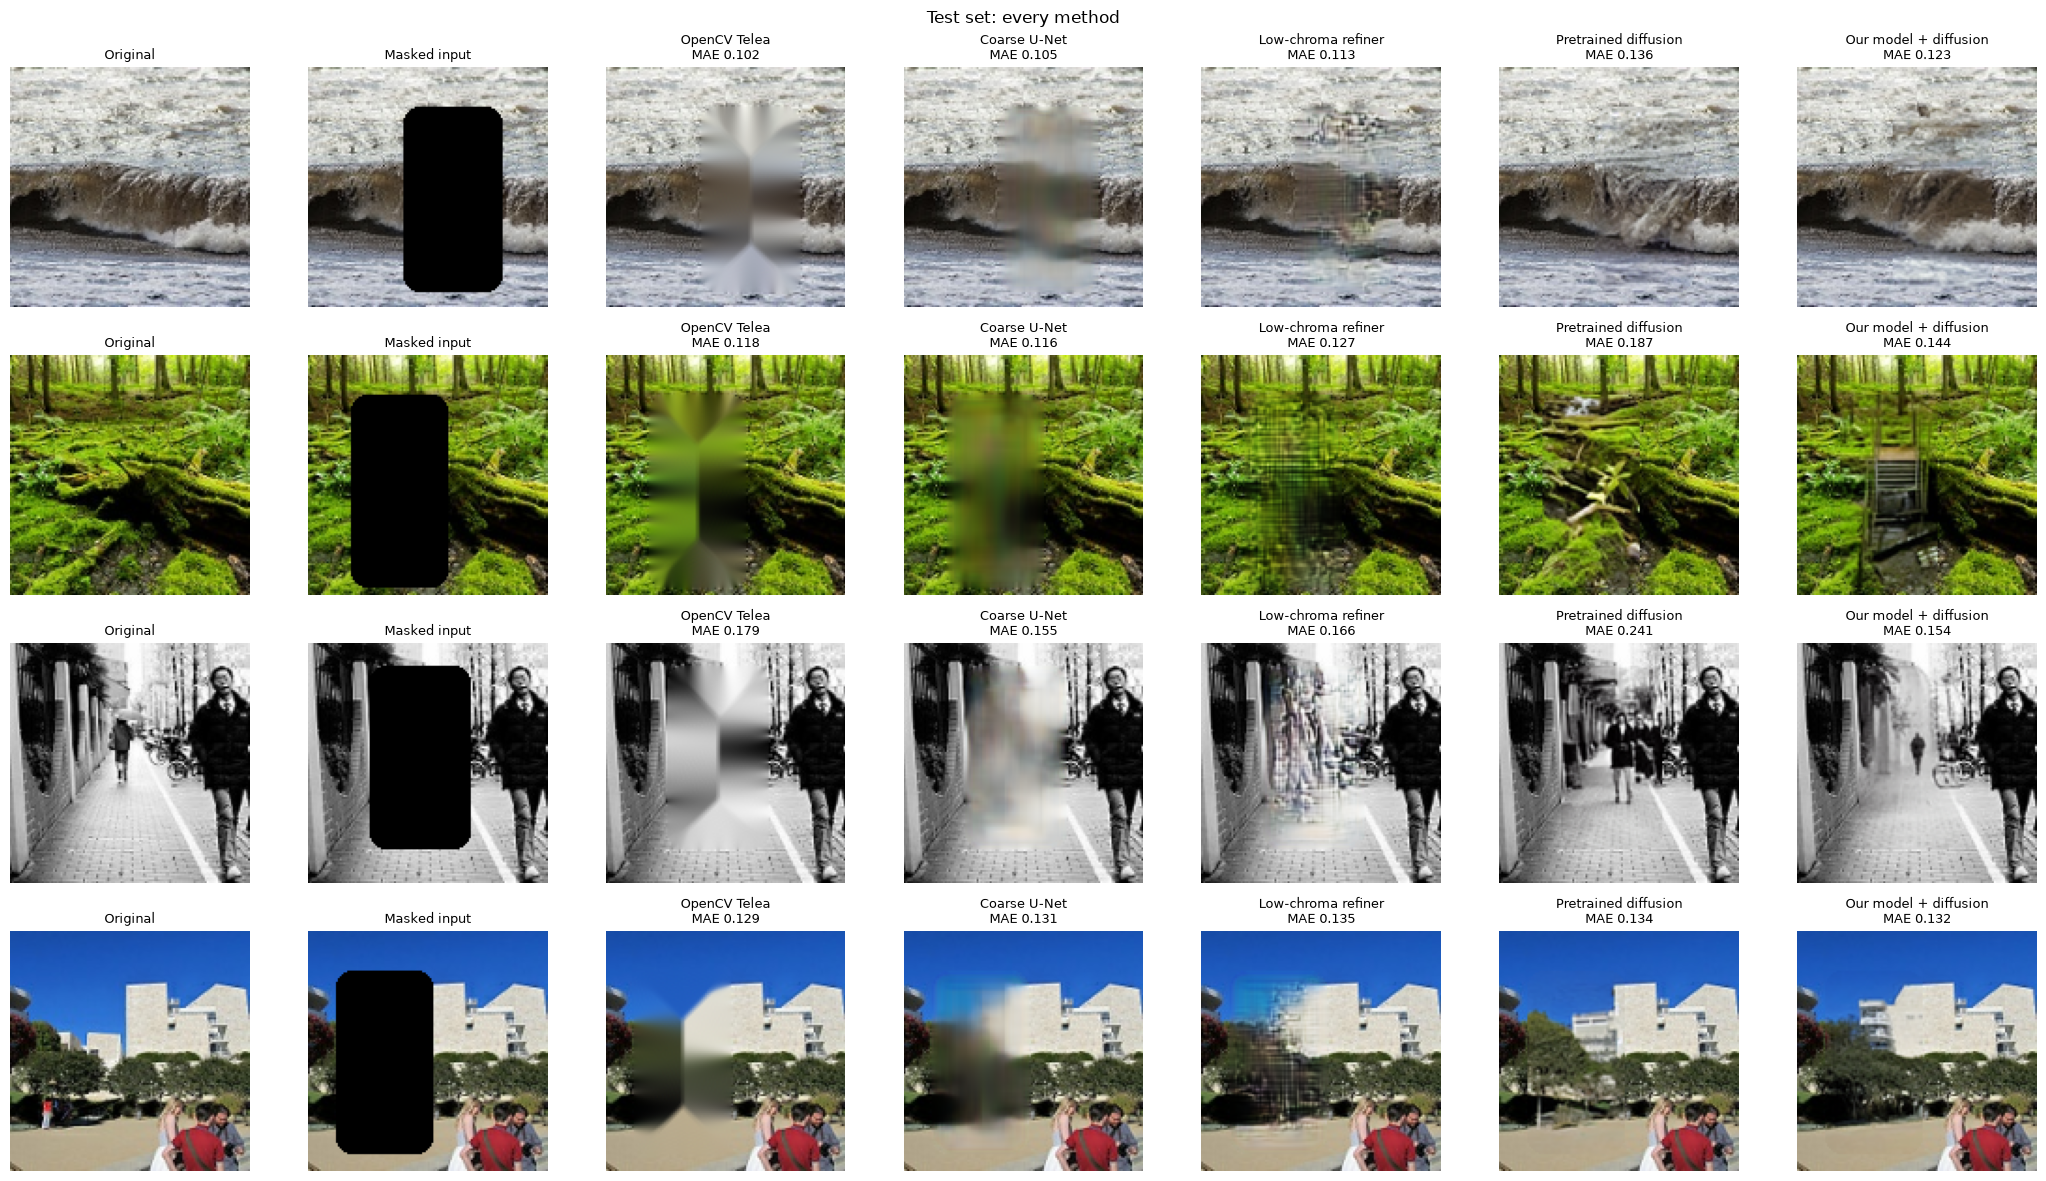

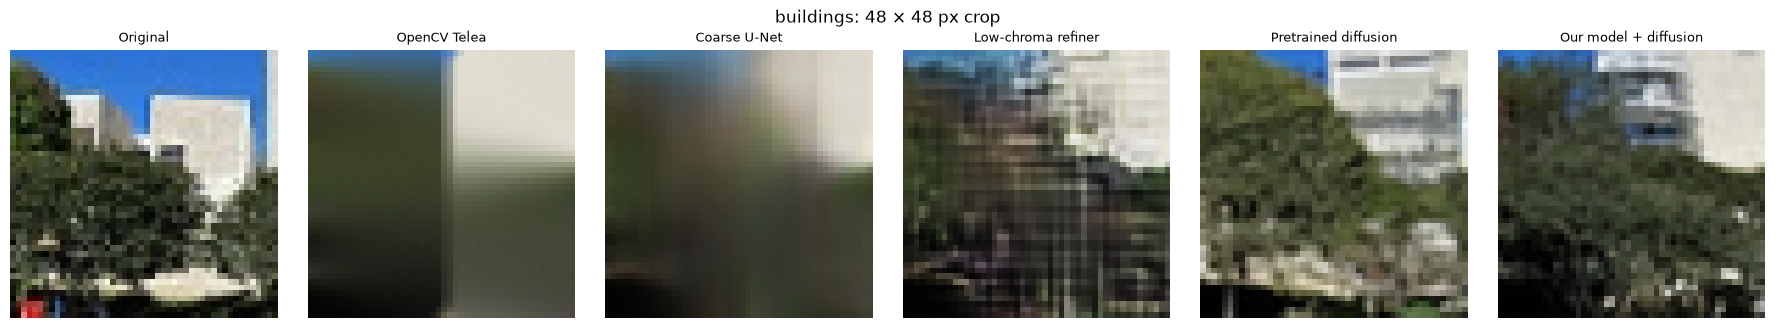

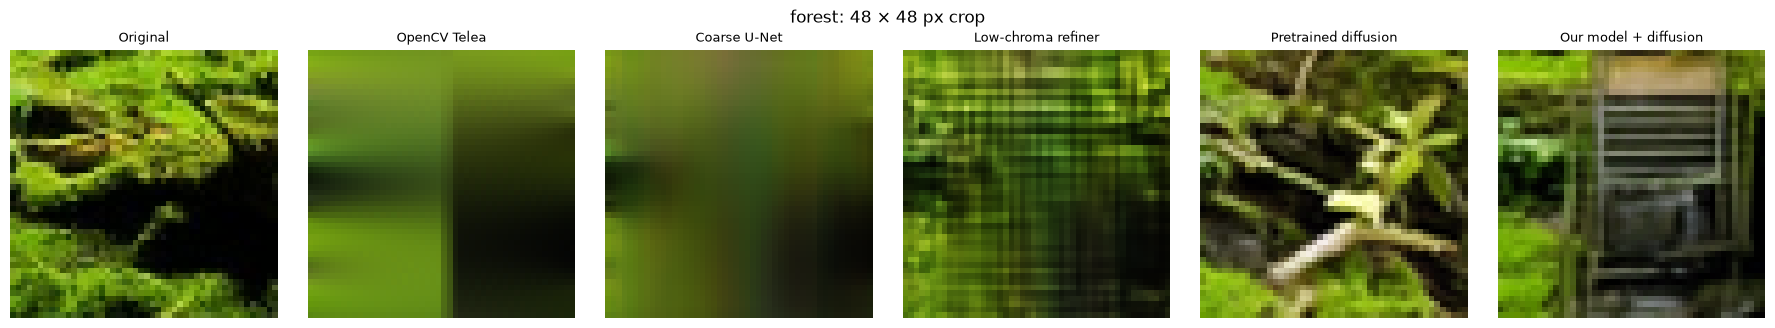

In [8]:
test_examples = test_set.example_indices()
show_comparison(
    test_set, {name: reconstructions[name] for name in METHODS}, test_examples,
    "Test set: every method",
)
for category, index in zip(
    ["buildings", "forest"], test_set.example_indices(["buildings", "forest"])
):
    show_zoom(
        test_set, {name: reconstructions[name] for name in METHODS}, index,
        title=f"{category}: 48 × 48 px crop",
    )

## Test Results

**Both of our models beat the classical baseline on perceptual distance and
KID, and the coarse U-Net also on pixel error. The pretrained stage lowers our
model's perceptual distance without changing its pixel error. Starting the
pretrained model from our fill improves it on both. The test figures agree
with validation.**

- **1. Our models against OpenCV Telea.**
  - The coarse U-Net is better on all three measures:
    - masked MAE −0.0134 (95% CI [−0.0150, −0.0119]; lower on 88% of images);
    - perceptual distance −0.201 ([−0.218, −0.183]; 91%);
    - KID × 1000 −9.2 (lower in 100% of subsets).
  - The low-chroma refiner is much better on perceptual distance, −0.371
    ([−0.397, −0.346]; 96%), and on KID, −14.8 (100%). Its masked MAE does
    not differ: −0.0006 ([−0.0023, +0.0011]; 48%).
- **2. The refiner against the U-Net.** As on validation, the refiner trades
  pixel error for perceptual quality.
  - Masked MAE rises by 0.0128 ([+0.0119, +0.0138]): three times the 0.004
    between training runs. The refiner is lower on only 5% of images.
  - Perceptual distance falls by 0.170 ([−0.185, −0.155]; 90%), and
    KID × 1000 by 5.6 (100%).
  - Its fill has fine detail close to the truth's: detail ratios of 0.81
    (luma) and 1.10 (chroma), against 0.03 and 0.31 for the U-Net.
  - It also keeps the grid seen on validation: 2-px components of 0.027 and
    0.028, against 0.001 and 0.002 in the true images.
  - On 24% of images it has more than twice the true colour detail.
- **3. What the pretrained stage adds to our model.** Our model + diffusion
  has the lowest perceptual distance of all five methods.
  - Against the refiner, perceptual distance falls by 0.119
    ([−0.136, −0.102]; 76% of images), and KID × 1000 by 1.9 (lower in 99% of
    subsets).
  - Masked MAE is 0.0016 lower, with interval [−0.0033, −0.0000].
    - That interval excludes zero by less than 0.0001.
    - The difference is smaller than the 0.004 between two training runs of
      our refiner.
    - The chain is lower on only 48% of images.
    - We therefore count pixel error as unchanged.
  - The texture changes:
    - The 2-px grid components fall to 0.007 and 0.012, the level of the
      diffusion model alone (0.007 and 0.015).
    - The 4-px components, 0.002 and 0.001, are near the true images' 0.001
      and 0.005.
    - Images with excess colour detail fall from 24% to 6%.
    - The cost is fine detail: the luma ratio is 0.47, against 0.81.
- **4. What our stage 1 adds to the pretrained model.** Starting from our
  fill instead of noise:
  - lowers masked MAE by 0.035 ([−0.041, −0.030]; 86% of images);
  - lowers perceptual distance by 0.226 ([−0.273, −0.183]; 75%);
  - lowers KID × 1000 by 0.9 (88% of subsets), which is small next to
    standard deviations of about 2.

  Alone, the pretrained model has the highest masked MAE of the five methods
  (0.138, against 0.105 for OpenCV). It fills the hole with content that
  looks real but does not match the hidden truth.

**Other observations.**

- **KID.**
  - OpenCV (15.2, standard deviation 3.6) and the U-Net (6.0, standard
    deviation 2.3) are clearly far from the true images.
  - The refiner (0.4), the diffusion model alone (−0.6), and the chain
    (−1.5) are each within one standard deviation (about 2) of zero. With
    400 images, their results cannot be told apart from the true images by
    this measure.
  - The KID estimator is unbiased, so it can be slightly negative.
- **Agreement with validation.**

  | Measure | Split | U-Net | Refiner | OpenCV |
  | --- | --- | --- | --- | --- |
  | Masked MAE | Validation | 0.0932 | 0.1059 | 0.1053 |
  | Masked MAE | Test | 0.0915 | 0.1043 | 0.1049 |
  | Perceptual distance | Validation | 0.880 | 0.708 | 1.061 |
  | Perceptual distance | Test | 0.884 | 0.714 | 1.085 |

  The refiner's paired differences from the U-Net were +0.0127 and −0.172
  on validation, against +0.0128 and −0.170 on test. Choosing the models on
  validation did not overfit them to it.
- **By category** (means, without intervals):
  - Sea is the easiest category for every method, with masked MAE from
    0.058 to 0.107.
  - The chain has the lowest perceptual distance in every category.
  - Against the refiner, the chain's masked MAE is lower on buildings
    (0.107 against 0.118) and similar elsewhere.
  - On sea, the diffusion model alone has a higher perceptual distance than
    the U-Net (0.888 against 0.709).
- **Near-duplicate.** Without `forest/22993.jpg`, no masked MAE changes by
  more than 0.0001, and no perceptual distance by more than 0.002.
- **Visual check.**
  - In the four examples, the chain gives the most coherent fills: the wave
    continues across the hole, and the trees and building extend in the
    buildings photo.
  - The diffusion model alone produces sharper content, but it is invented:
    a fallen branch in the forest, and several walkers in the street where
    the original has one.
  - The chain invents too. In the forest image, it fills the hole with a
    ladder-like structure of horizontal bars, where the refiner's fill has
    its strongest horizontal and vertical stripes.
  - At strength 0.7, the pretrained model probably keeps part of our fill's
    structure, its artifacts included. This is one example; it was not
    measured.
- **Run time per image on the Apple M5.**

  | Method | Seconds | How it ran |
  | --- | --- | --- |
  | OpenCV Telea | 0.001 | in batches |
  | Coarse U-Net | 0.002 | in batches |
  | Low-chroma refiner | 0.007 | in batches |
  | Pretrained diffusion | 10.9 | one image at a time |
  | Our model + diffusion | 7.9 | one image at a time |

  The chain is faster than the diffusion model alone because at strength
  0.7 it runs 21 of the 30 steps.

**Limits.**

- **Training runs.** Each of our models was trained once. The intervals
  cover the choice of images, not the training run. The 0.004 between runs
  was measured on validation.
- **Resolution.** Every measure is at 128 × 128.
  - The diffusion model works at 512 × 512, and reducing its output removes
    part of its detail.
  - The app works on the photo's own resolution, so these figures describe
    its fill only approximately.
- **Diffusion settings.** The strength 0.7 was chosen by eye, not tuned.
  Diffusion used one seed per image.
- **Masked MAE.** It penalizes any plausible fill that differs from the
  hidden truth, so it favours blurry averages such as the U-Net's.
  Perceptual distance and KID measure the other side of that trade-off.

**Conclusion.**

- Among the methods trained in this project:
  - The coarse U-Net has the lowest pixel error of all five methods.
  - The low-chroma refiner gives up part of that pixel accuracy for a large
    perceptual gain.
- Chaining the refiner with the pretrained model:
  - gives the best perceptual distance of the five methods;
  - keeps our model's pixel error;
  - beats the pretrained model used alone on masked MAE and perceptual
    distance.
- These figures, from a single use of the reserved test set, are the
  project's final results.